In [47]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [48]:
%%bash
# Check and unzip if directory does not exist
[ ! -d "/content/dataset" ] && unzip -q "/content/drive/MyDrive/Colab Notebooks/facial emotion detection/fer2013.zip" -d "/content/dataset" || echo "Folder already exists!"

Folder already exists!


In [49]:
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D, MaxPooling2D, Input, BatchNormalization
from keras.models import Sequential
from keras.preprocessing import image_dataset_from_directory
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

In [50]:
# Define paths and constants
TRAIN_DIR = 'dataset/train'
TEST_DIR = 'dataset/test'
IMAGE_SIZE = (48, 48)
BATCH_SIZE = 64
NUM_CLASSES = 7   # angry, digust, fear, happy, neutral, sad, surprise

In [51]:
# Load train and test data
train_ds = image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42,
    color_mode='grayscale',
    label_mode='categorical'
)

test_ds = image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    seed=42,
    color_mode='grayscale',
    label_mode='categorical'
)

class_names = train_ds.class_names
print(class_names)

train_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

Found 28709 files belonging to 7 classes.
Found 7178 files belonging to 7 classes.
['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


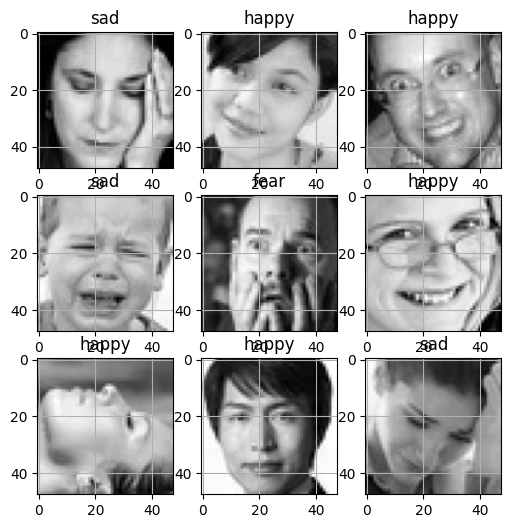

In [52]:
# Plot the data
plt.figure(figsize=(6, 6))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i], cmap='gray')
        plt.title(class_names[np.argmax(labels[i])])
        plt.grid(True)

In [53]:
# Build model
input_shape = IMAGE_SIZE + (1,)
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
    # BatchNormalization(),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    # BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.25),

    # Conv2D(64, (3, 3), activation='relu', padding='same'),
    # BatchNormalization(),
    # Conv2D(64, (3, 3), activation='relu', padding='same'),
    # BatchNormalization(),
    # MaxPooling2D(2, 2),
    # Dropout(0.25),

    Conv2D(128, (3, 3), activation='relu', padding='same'),
    # BatchNormalization(),
    MaxPooling2D(2, 2),
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    # BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.25),

    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_13 (Conv2D)              │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,421,959 (5.42 MB)

 Trainable params: 1,421,959 (5.42 MB)

 Non-trainable params: 0 (0.00 B)

In [54]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [55]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    verbose=1,
    restore_best_weights=True)

model_checkpoint = ModelCheckpoint('facial_emotion_detection.keras',
                                   monitor='val_accuracy',
                                   save_best_only=True,
                                   mode='max')

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.1,
    patience=5,
    verbose=1,
    min_lr=1e-6)

In [56]:
#Train the model
EPOCHS = 30

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping, model_checkpoint, reduce_lr]
)

Epoch 1/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.2958 - loss: 1.9616 - val_accuracy: 0.3782 - val_loss: 1.5800 - learning_rate: 0.0010
Epoch 2/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.3943 - loss: 1.5541 - val_accuracy: 0.4459 - val_loss: 1.4387 - learning_rate: 0.0010
Epoch 3/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.4462 - loss: 1.4391 - val_accuracy: 0.4673 - val_loss: 1.3618 - learning_rate: 0.0010
Epoch 4/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.4786 - loss: 1.3619 - val_accuracy: 0.4961 - val_loss: 1.3016 - learning_rate: 0.0010
Epoch 5/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.5054 - loss: 1.2950 - val_accuracy: 0.5171 - val_loss: 1.2487 - learning_rate: 0.0010
Epoch 6/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.5216 - loss: 1.2582 - val_accuracy: 0.5220 - val_loss: 1.2161 - learning_rate: 0.0010
Epoch 7/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.5383 - loss: 1

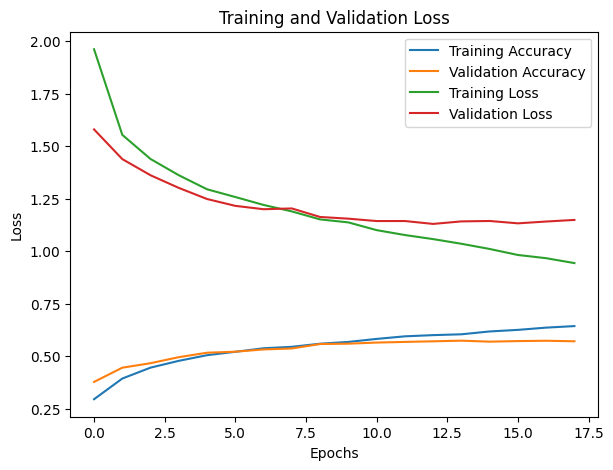

In [57]:
plt.figure(figsize=(15, 5))

accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(accuracy, label='Training Accuracy')
plt.plot(val_accuracy, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')

# Loss graph
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')

plt.show()

In [58]:
test_loss, test_accuracy = model.evaluate(test_ds)
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_accuracy:.4f}')

113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5715 - loss: 1.1302
Test Loss: 1.1302
Test Accuracy: 0.5715


In [19]:
model.save('/content/drive/MyDrive/Colab Notebooks/facial emotion detection/facial_emotion_detection.keras')
print('Model saved successfully!')

Model saved successfully!
